In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

I0000 00:00:1787022703.465821    4795 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787022706.824746    4795 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1787022716.194932    4795 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0


In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

y_train = y_train.flatten()
y_test = y_test.flatten()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Training data:", x_train.shape)
print("Test data:", x_test.shape)

Training data: (50000, 32, 32, 3)
Test data: (10000, 32, 32, 3)


In [4]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomTranslation(0.1, 0.1)
])

In [5]:
cnn = models.Sequential([
    data_augmentation,

    layers.Conv2D(32, (3, 3), activation="relu", padding="same",
                  input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn.summary()

/home/pl1/.local/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [12]:
history_cnn = cnn.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2
)

mlp = models.Sequential([
    layers.Flatten(input_shape=(32, 32, 3)),
    layers.Dense(512, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

mlp.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_mlp = mlp.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.5514 - loss: 1.2608 - val_accuracy: 0.6432 - val_loss: 1.0303
Epoch 2/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.5561 - loss: 1.2524 - val_accuracy: 0.6522 - val_loss: 1.0023
Epoch 3/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.5615 - loss: 1.2374 - val_accuracy: 0.6424 - val_loss: 1.0588
Epoch 4/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.5681 - loss: 1.2270 - val_accuracy: 0.6351 - val_loss: 1.0606
Epoch 5/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.5697 - loss: 1.2232 - val_accuracy: 0.6325 - val_loss: 1.0797
Epoch 6/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.5748 - loss: 1.2118 - val_accuracy: 0.6399 - val_loss: 1.0513
Epoch 7/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.5750 - loss: 1.2072 - val_accuracy: 0.6416 - val_loss: 1.0247
Epoch 8/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.5780 - loss: 1.2034 - val_accu

/home/pl1/.local/lib/python3.10/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.1716 - loss: 2.1890 - val_accuracy: 0.2177 - val_loss: 2.0611
Epoch 2/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.1970 - loss: 2.0907 - val_accuracy: 0.2715 - val_loss: 2.0347
Epoch 3/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.2169 - loss: 2.0457 - val_accuracy: 0.2644 - val_loss: 2.0042
Epoch 4/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.2258 - loss: 2.0305 - val_accuracy: 0.2277 - val_loss: 2.0127
Epoch 5/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.2293 - loss: 2.0269 - val_accuracy: 0.2608 - val_loss: 2.0106
Epoch 6/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.2283 - loss: 2.0201 - val_accuracy: 0.2734 - val_loss: 1.9884
Epoch 7/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.2312 - loss: 2.0076 - val_accuracy: 0.2618 - val_loss: 1.9990
Epoch 8/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.2326 - loss: 2.0084 - val_accu

In [13]:
mlp_loss, mlp_accuracy = mlp.evaluate(x_test, y_test, verbose=0)

print("MLP Test Loss:", mlp_loss)
print("MLP Test Accuracy:", mlp_accuracy)

print("\n===== FINAL RESULTS =====")
print(f"CNN Test Accuracy: {cnn_accuracy:.4f}")
print(f"MLP Test Accuracy: {mlp_accuracy:.4f}")
print(f"CNN Improvement: {(cnn_accuracy - mlp_accuracy) * 100:.2f}%")

MLP Test Loss: 1.977182388305664
MLP Test Accuracy: 0.27889999747276306

===== FINAL RESULTS =====
CNN Test Accuracy: 0.6321
MLP Test Accuracy: 0.2789
CNN Improvement: 35.32%


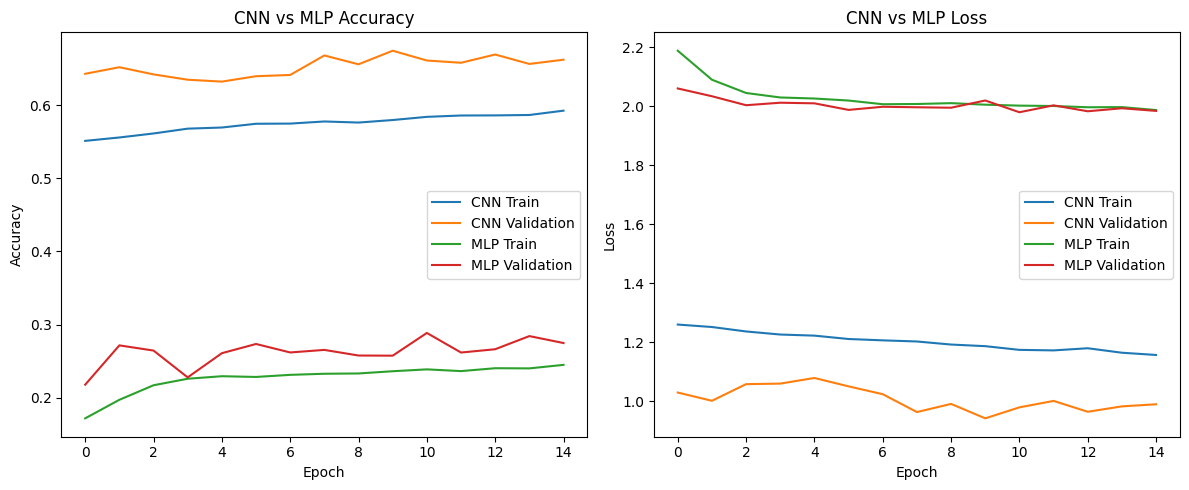

In [14]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["accuracy"], label="CNN Train")
plt.plot(history_cnn.history["val_accuracy"], label="CNN Validation")
plt.plot(history_mlp.history["accuracy"], label="MLP Train")
plt.plot(history_mlp.history["val_accuracy"], label="MLP Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN vs MLP Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["loss"], label="CNN Train")
plt.plot(history_cnn.history["val_loss"], label="CNN Validation")
plt.plot(history_mlp.history["loss"], label="MLP Train")
plt.plot(history_mlp.history["val_loss"], label="MLP Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN vs MLP Loss")
plt.legend()

plt.tight_layout()
plt.show()